In [1]:
import numpy as np
import pandas as pd
import pyagrum as gum
import pyagrum.lib.notebook as gnb
import pyagrum.lib.dynamicBN as gdyn

from cross_impact.model import build_network, UncertaintyFactor, CrossImpactNetwork
from cross_impact.pyagrum_import import marginals_and_joint_from_pyagrum
from cross_impact.pyagrum_export import graft_onto_pyagrum
from cross_impact.model import cross_impacts_from_joint

In [2]:
# The uncertainty factors, or dnb nodes
factortuples = [
    # Ajattomat
    ("GER", 2, ()),  # 0
    ("OMA", 2, ()),  # 1

    # Nykyhetki
    ("PIS0", 4, ()), # 2
    ("PIH0", 5, (2,)), # 3
    ("LYS0", 4, (2,3,)), # 4
    ("LYH0", 7, (2,3,4,)), # 5

    # Viive
    ("PISt", 4, (2,3,4,5,)), # 6
    ("PIHt", 5, (0,1,3,5,6,)), # 7
    ("LYSt", 4, (0,1,4,5,6,7,)), # 8
    ("LYHt", 7, (0,1,5,6,7,8,)), # 9
    ("ASTt", 3, (0,1,7,9,)), # 10
    ("KUOt", 2, (6,7,8,9,)), # 11
]
factors = [UncertaintyFactor(factor[0], factor[1], factor[2]) for factor in factortuples]
desc = """
Tilalistaus:
* Lyhytaikainen sairaus (LYS)
	* 0 Terve (ei akuuttia tilaa)
	* 1 Lievä (luultavasti paranee itsestään ilman hoitoa, esim. flunssa)
	* 2 Vakava (Vaatii hoitoa tai pitkäaikaisten ongelmien riski on suuri)
	* 3 Hengenvaarallinen (Vaatii välitönta hoitoa tai kuoleman todennäköisyys on suuri)
* Pitkäaikainen sairaus (PIS)
	* 0 Terve (Ei pitkäaikaisia vaivoja)
	* 1 Lievä (Ei vaadi aktiivista hoitoa)
	* 2 Vakava (Vaatii jatkuvaa hoitoa)
	* 3 Hengenvaarallinen (Vaatii jatkuvaa hoitoa kuoleman välttämiseksi)
* Hoitoonhakeutumisalttius (HHA)
	* 0 Ramppaaja (Käy tarpeettomasti hakemassa hoitoa)
	* 1 Normaali (Hakeutuu hoitoon lähinnä vakavissa tilanteissa)
	* 2 Änkyrä (Ei hakeudu hoitoon ellei joku pakota)
* Lyhytaikainen hoito (akuutti) (LYH)
	* 0 Ei mitään
	* 1 Terveyskeskus
	* 2 Päivystys
	* 3 Sairaala
	* 4 Kotisairaala????
	* 5 Lyhytaikainen kuntoutus
	* 6 Arviointiyksikkö
* Pitkäaikainen hoito (PIH)
	* 0 Ei mitään
	* 1 Omaishoito
	* 2 Kotihoito
	* 3 Ympärivuorokaiutinen palveluasuminen
	* 4 Laitospalvelu
* Geriatriapalikka (Hoitaako geriatritiimi päivystyksessä) (GER)
	* 0 Kyllä
	* 1 Ei
* Omalääkäri (OMA)
	* 0 Kyllä
	* 1 Ei
* Asiakastyytyväisyys (AST)
	* 0 Hyvä
	* 1 Keskinkertainen
	* 2 Huono
* Kuollut (KUO)
	* 0 Kyllä
	* 1 Ei
"""

In [3]:
# marginals for each uncertainty factor
hha_mar = np.array([0.3, 0.4, 0.3])
ger_mar = np.array([0.7, 0.3])
oma_mar = np.array([0.5, 0.5])
pis_mar = np.array([0.0993, 0.388, 0.4343, 0.0784])
pih_mar = np.array([0.7467, 0.042, 0.14, 0.0663, 0.005])
lys_mar = np.array([0.9637, 0.0099, 0.0185, 0.0079])
lyh_mar = np.array([0.950, 0.031, 0.005, 0.01, 0.001, 0.003, 0])
ast_mar = np.array([0.5, 0.2, 0.3])
kuo_mar = np.array([0.00015, 1-0.00015])

In [4]:
df = pd.read_csv("ci-data/cross-impact-healthcare-sheet.csv")
df = df.iloc[8:, 3:]
df = df.astype(float)
ls = list(map(lambda x : x[1], factortuples))
print(ls)
lo = []
for i, l in enumerate(ls):
    lo.append(sum(ls[:i]))
print(lo)
print("---")

cross_impacts = {}
for fi, factor in enumerate(factortuples):
    for parent_index in factor[2]:
        print(f"({parent_index}, {fi})")
        factor_dim = factor[1]
        parent_dim = factortuples[parent_index][1]
        #cross_impacts[(parent_index, fi)] = np.zeros((parent_dim, factor_dim))
        cross_impacts[(parent_index, fi)] = np.array(df.iloc[lo[parent_index]:lo[parent_index]+ls[parent_index],lo[fi]:lo[fi]+ls[fi]])
        print(cross_impacts[parent_index, fi])

[2, 2, 4, 5, 4, 7, 4, 5, 4, 7, 3, 2]
[0, 2, 4, 8, 13, 17, 24, 28, 33, 37, 44, 47]
---
(2, 3)
[[ 3. -3. -3. -3. -3.]
 [ 2. -2. -2. -2. -2.]
 [-2.  2.  2.  1.  1.]
 [-3.  2.  2.  3.  3.]]
(2, 4)
[[3. 2. 1. 0.]
 [2. 3. 2. 1.]
 [1. 2. 3. 2.]
 [0. 1. 2. 3.]]
(3, 4)
[[1. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]
(2, 5)
[[ 2. -2. -2. -2. -2. -2. -2.]
 [ 1. -1. -1. -1. -1. -1. -1.]
 [-1.  1.  1.  1.  1.  1.  1.]
 [-2.  2.  2.  2.  2.  2.  2.]]
(3, 5)
[[ 1.  0.  0. -1. -1. -1. -1.]
 [ 0.  1.  0.  0.  0.  0.  0.]
 [ 0.  1.  1.  0. -1.  0.  0.]
 [ 0.  0.  0.  0.  0.  1.  1.]
 [ 0.  0.  0.  0.  0.  1.  1.]]
(4, 5)
[[ 3.  1.  1. -2. -3. -3. -3.]
 [ 1.  1.  1. -1. -2. -3. -3.]
 [-1.  2.  3.  3.  3.  2.  1.]
 [-3. -3.  3.  3.  3.  1. -1.]]
(2, 6)
[[ 3.  1. -1. -3.]
 [ 1.  3.  1. -1.]
 [-1.  1.  3.  1.]
 [-3. -2.  1.  3.]]
(3, 6)
[[-1.  0.  1.  1.]
 [ 0.  0. -1. -1.]
 [ 0.  0. -2. -2.]
 [ 0.  0. -2. -2.]
 [ 0.  0.  0. -2.]]
(4, 6)
[[3. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0

In [5]:
network = CrossImpactNetwork(
    factors=factors,
    marginals=[
        ger_mar,
        oma_mar,
        
        pis_mar,
        pih_mar,
        lys_mar,
        lyh_mar,
        
        pis_mar,
        pih_mar,
        lys_mar,
        lyh_mar,
        ast_mar,
        kuo_mar,
    ],
    cross_impacts=cross_impacts,
)
built = build_network(network, mode="independent", initial_joint=None)

(CVXPY) Nov 05 03:06:57 PM: Your problem has 2 variables, 3 constraints, and 0 parameters.
(CVXPY) Nov 05 03:06:57 PM: It is compliant with the following grammars: DCP, DQCP
(CVXPY) Nov 05 03:06:57 PM: DCP verification time: 0.0002 seconds.
(CVXPY) Nov 05 03:06:57 PM: Expression tree has 2 nodes.
(CVXPY) Nov 05 03:06:57 PM: (If you need to solve this problem multiple times, but with different data, consider using parameters.)
(CVXPY) Nov 05 03:06:57 PM: CVXPY will first compile your problem; then, it will invoke a numerical solver to obtain a solution.
(CVXPY) Nov 05 03:06:57 PM: Your problem is compiled with the CPP canonicalization backend.
(CVXPY) Nov 05 03:06:57 PM: Compiling problem (target solver=CLARABEL).
(CVXPY) Nov 05 03:06:57 PM: Reduction chain: Dcp2Cone -> CvxAttr2Constr -> EliminateZeroSized -> ConeMatrixStuffing -> CLARABEL
(CVXPY) Nov 05 03:06:57 PM: Applying reduction Dcp2Cone
(CVXPY) Nov 05 03:06:57 PM: Applying reduction CvxAttr2Constr
(CVXPY) Nov 05 03:06:57 PM: App

                                     CVXPY                                     
                                     v1.9.2                                    
-------------------------------------------------------------------------------
                                  Compilation                                  
-------------------------------------------------------------------------------
-------------------------------------------------------------------------------
                                Numerical solver                               
-------------------------------------------------------------------------------
-------------------------------------------------------------
           Clarabel.rs v0.11.1  -  Clever Acronym                

                   (c) Paul Goulart                          
                University of Oxford, 2022                   
-------------------------------------------------------------

problem:
  variables     = 2
  constraints  

(CVXPY) Nov 05 03:06:57 PM: Problem status: optimal
(CVXPY) Nov 05 03:06:57 PM: Optimal value: 0.000e+00
(CVXPY) Nov 05 03:06:57 PM: Compilation took 1.242e-02 seconds
(CVXPY) Nov 05 03:06:57 PM: Solver (including time spent in interface) took 2.443e-03 seconds
(CVXPY) Nov 05 03:06:57 PM: Your problem has 2 variables, 3 constraints, and 0 parameters.
(CVXPY) Nov 05 03:06:57 PM: It is compliant with the following grammars: DCP, DQCP
(CVXPY) Nov 05 03:06:57 PM: DCP verification time: 0.0001 seconds.
(CVXPY) Nov 05 03:06:57 PM: Expression tree has 2 nodes.
(CVXPY) Nov 05 03:06:57 PM: (If you need to solve this problem multiple times, but with different data, consider using parameters.)
(CVXPY) Nov 05 03:06:57 PM: CVXPY will first compile your problem; then, it will invoke a numerical solver to obtain a solution.
(CVXPY) Nov 05 03:06:57 PM: Your problem is compiled with the CPP canonicalization backend.
(CVXPY) Nov 05 03:06:57 PM: Compiling problem (target solver=CLARABEL).
(CVXPY) Nov 05 

  0  +0.0000e+00  -0.0000e+00  0.00e+00  2.84e-01  6.50e-01  1.00e+00  1.13e+00   ------   
  1  +0.0000e+00  -8.8477e-02  8.85e-02  3.61e-02  1.19e-01  6.78e-03  1.59e-01  8.79e-01  
  2  +0.0000e+00  -7.0454e-04  7.05e-04  3.94e-04  1.42e-03  3.00e-04  1.93e-03  9.90e-01  
  3  +0.0000e+00  -7.0353e-06  7.04e-06  3.94e-06  1.42e-05  3.00e-06  1.93e-05  9.90e-01  
  4  +0.0000e+00  -7.0352e-08  7.04e-08  3.94e-08  1.42e-07  3.00e-08  1.93e-07  9.90e-01  
  5  +0.0000e+00  -7.0352e-10  7.04e-10  3.94e-10  1.42e-09  3.00e-10  1.93e-09  9.90e-01  
---------------------------------------------------------------------------------------------
Terminated with status = Solved
solve time = 78.769µs
-------------------------------------------------------------------------------
                                    Summary                                    
-------------------------------------------------------------------------------
                                     CVXPY                  

(CVXPY) Nov 05 03:06:57 PM: Problem status: optimal
(CVXPY) Nov 05 03:06:57 PM: Optimal value: 0.000e+00
(CVXPY) Nov 05 03:06:57 PM: Compilation took 9.090e-03 seconds
(CVXPY) Nov 05 03:06:57 PM: Solver (including time spent in interface) took 1.829e-03 seconds
(CVXPY) Nov 05 03:06:57 PM: Your problem has 4 variables, 5 constraints, and 0 parameters.
(CVXPY) Nov 05 03:06:57 PM: It is compliant with the following grammars: DCP, DQCP
(CVXPY) Nov 05 03:06:57 PM: DCP verification time: 0.0000 seconds.
(CVXPY) Nov 05 03:06:57 PM: Expression tree has 2 nodes.
(CVXPY) Nov 05 03:06:57 PM: (If you need to solve this problem multiple times, but with different data, consider using parameters.)
(CVXPY) Nov 05 03:06:57 PM: CVXPY will first compile your problem; then, it will invoke a numerical solver to obtain a solution.
(CVXPY) Nov 05 03:06:57 PM: Your problem is compiled with the CPP canonicalization backend.
(CVXPY) Nov 05 03:06:57 PM: Compiling problem (target solver=CLARABEL).
(CVXPY) Nov 05 

  0  +0.0000e+00  -0.0000e+00  0.00e+00  2.27e-01  6.67e-01  1.00e+00  1.00e+00   ------   
  1  +0.0000e+00  -6.8745e-02  6.87e-02  2.17e-02  1.07e-01  7.15e-03  1.06e-01  9.08e-01  
  2  +0.0000e+00  -6.1749e-04  6.17e-04  2.14e-04  1.04e-03  1.15e-04  1.10e-03  9.90e-01  
  3  +0.0000e+00  -6.1707e-06  6.17e-06  2.14e-06  1.03e-05  1.15e-06  1.10e-05  9.90e-01  
  4  +0.0000e+00  -6.1707e-08  6.17e-08  2.14e-08  1.03e-07  1.15e-08  1.10e-07  9.90e-01  
  5  +0.0000e+00  -6.1707e-10  6.17e-10  2.14e-10  1.03e-09  1.15e-10  1.10e-09  9.90e-01  
---------------------------------------------------------------------------------------------
Terminated with status = Solved
solve time = 57.288µs
-------------------------------------------------------------------------------
                                    Summary                                    
-------------------------------------------------------------------------------
                                     CVXPY                  

... (8 outputs left out)

(CVXPY) Nov 05 03:07:09 PM: Problem status: optimal_inaccurate
(CVXPY) Nov 05 03:07:09 PM: Optimal value: 6.496e+00
(CVXPY) Nov 05 03:07:09 PM: Compilation took 3.740e-02 seconds
(CVXPY) Nov 05 03:07:09 PM: Solver (including time spent in interface) took 5.964e+00 seconds
(CVXPY) Nov 05 03:07:09 PM: Your problem has 420 variables, 143 constraints, and 0 parameters.
(CVXPY) Nov 05 03:07:09 PM: It is compliant with the following grammars: DCP, DQCP
(CVXPY) Nov 05 03:07:09 PM: DCP verification time: 0.0003 seconds.
(CVXPY) Nov 05 03:07:09 PM: Expression tree has 5 nodes.
(CVXPY) Nov 05 03:07:09 PM: (If you need to solve this problem multiple times, but with different data, consider using parameters.)
(CVXPY) Nov 05 03:07:09 PM: CVXPY will first compile your problem; then, it will invoke a numerical solver to obtain a solution.
(CVXPY) Nov 05 03:07:09 PM: Your problem is compiled with the CPP canonicalization backend.
(CVXPY) Nov 05 03:07:09 PM: Compiling problem (target solver=OSQP).
(CVX

10000   6.4962e+00   1.37e-05   4.84e-06  -3.76e-04   1.37e-05   1.00e-01    5.96e+00s

status:               solved inaccurate
number of iterations: 10000
optimal objective:    6.4962
dual objective:       6.4965
duality gap:          -3.7562e-04
primal-dual integral: 2.3464e+05
run time:             5.96e+00s
optimal rho estimate: 8.93e-02

-------------------------------------------------------------------------------
                                    Summary                                    
-------------------------------------------------------------------------------
                                     CVXPY                                     
                                     v1.9.2                                    
-------------------------------------------------------------------------------
                                  Compilation                                  
-------------------------------------------------------------------------------
---------------

(CVXPY) Nov 05 03:07:09 PM: Problem status: optimal_inaccurate
(CVXPY) Nov 05 03:07:09 PM: Optimal value: 1.200e+01
(CVXPY) Nov 05 03:07:09 PM: Compilation took 1.160e-02 seconds
(CVXPY) Nov 05 03:07:09 PM: Solver (including time spent in interface) took 2.668e-01 seconds


5200   1.2001e+01   1.52e-04   3.42e-05   3.64e-06   1.52e-04   6.06e-01    1.40e-01s
5400   1.2001e+01   1.56e-04   3.31e-05   5.76e-05   1.56e-04   6.06e-01    1.46e-01s
5600   1.2001e+01   1.59e-04   3.10e-05   7.67e-05   1.59e-04   6.06e-01    1.51e-01s
5800   1.2001e+01   1.62e-04   3.08e-05   6.27e-05   1.62e-04   6.06e-01    1.56e-01s
6000   1.2001e+01   1.66e-04   2.83e-05   7.97e-05   1.66e-04   6.06e-01    1.61e-01s
6200   1.2001e+01   1.69e-04   2.81e-05   6.60e-05   1.69e-04   6.06e-01    1.66e-01s
6400   1.2001e+01   1.72e-04   2.75e-05   8.02e-05   1.72e-04   6.06e-01    1.72e-01s
6600   1.2001e+01   1.74e-04   2.63e-05   1.21e-04   1.74e-04   6.06e-01    1.77e-01s
6800   1.2001e+01   1.77e-04   2.57e-05   1.87e-04   1.87e-04   6.06e-01    1.82e-01s
7000   1.2001e+01   1.79e-04   2.32e-05   2.48e-04   2.48e-04   6.06e-01    1.88e-01s
7200   1.2001e+01   1.82e-04   2.31e-05   2.35e-04   2.35e-04   6.06e-01    1.93e-01s
7400   1.2001e+01   1.84e-04   2.29e-05   2.44e-04   2

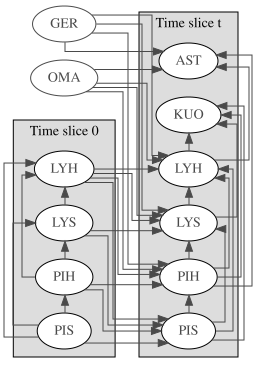

In [6]:
from cross_impact.pyagrum_export import to_pyagrum

bn = to_pyagrum(built)
gdyn.showTimeSlices(bn)

# HUOMIO! Lisää noodi, joka käsittelee kuolleen erikseen! eli siis kaikki tuo on ehdollistettu sillä, että henkilö on elossa.

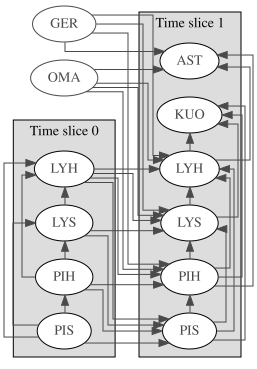

In [7]:
T = 2
dbn = gdyn.unroll2TBN(bn, T)
gdyn.showTimeSlices(dbn)

In [8]:
ie = gum.LazyPropagation(dbn)
gnb.sideBySide(ie.posterior("PIS0"), ie.posterior("PIS1"), ie.posterior("KUO1"))
for i in range(4):
    ie.setEvidence({"PIS0": i})
    ie.makeInference()
    gnb.sideBySide(ie.posterior("PIS0"), ie.posterior("PIS1"), ie.posterior("KUO1"))